# 04. Crash Bounds for Single Names (Martin and Shi 2025)

The first three guides worked with the market as a whole. This one asks
the question of [Martin and Shi (2025)](https://personal.lse.ac.uk/martiniw/oib_martin_shi_latest.pdf),
*Forecasting Crashes with a Smile*: what is the probability that **one
stock**, Apple or AIG, falls 20% in the next month?

Options on the stock give its risk-neutral distribution, exactly as index
options gave the market's in guide 02. But a risk-neutral probability
"cries wolf": it prices crash states at their marginal utility, not their
frequency, and the correction that worked for the index, dividing by the
investor's marginal utility, needs the *joint* distribution of the stock
and the market, which no option price reveals. Martin and Shi's answer is
to bound it. Given the two marginal distributions, the Fréchet-Hoeffding
theorem says how far apart the probability can be across every possible
dependence structure, and the lower bound, which is attained when the
stock and the market crash together, turns out to forecast crashes out of
sample with no parameter to estimate.

**In this guide**

- The data: the OptionMetrics volatility surface, and what it does not
  cover.
- The paper's Figure 1: the bounds for Apple and AIG, 1996 to 2022, and
  extended to the latest surface.
- The index on its own: the crash probability from the surface, checked
  against the monthly series Martin (2017) publishes.

The code is Riley Haas and Marija Jovicic's, from their Summer 2026
replication of the paper (`forecasting_crashes_smile`), used with their
permission. The computation runs in `src/single_name_bounds.py` as the
`single_names` task; this notebook loads its output.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from settings import config

OUTPUT_DIR = Path(config("OUTPUT_DIR"))
DATA_DIR = Path(config("DATA_DIR"))
MANUAL_DATA_DIR = Path(config("MANUAL_DATA_DIR"))

pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

HAVE_RESULTS = (OUTPUT_DIR / "single_name_bounds.parquet").exists() and (
    OUTPUT_DIR / "index_crash_probabilities.parquet"
).exists()
if not HAVE_RESULTS:
    print(
        "The single-name results are not built. They need the OptionMetrics pull\n"
        "from WRDS, which is not part of the public monitor: run `uv run doit single_names`\n"
        "with your WRDS username in .env, then rebuild. The rest of this notebook is\n"
        "skipped until then."
    )

## The data: the OptionMetrics volatility surface

Guides 01 and 02 used the exchange's settlement prices, one per listed
strike. Single-name options are not on the course's Databento license, so
this part uses what the academic literature uses: OptionMetrics' IvyDB on
WRDS, and specifically its **standardized volatility surface**, which the
vendor fits every day for every security at fixed maturities (30, 60, 91,
... days) and fixed deltas (10 to 90, puts and calls). Martin and Shi's
Appendix D filters on the surface's `dispersion`, a goodness-of-fit
measure, and keys moneyness off `impl_strike`, both of which exist only in
the surface table, so the surface is the paper's specification, not a
shortcut.

Three WRDS tables, pulled by `src/pull_optionmetrics.py` for the S&P 500,
Apple, and AIG at 30 and 91 days: the surface (`vsurfd{year}`, one table
per year), daily closes for the spot (`secprd{year}`), and the zero curve
(`zerocd`). The homework's one blank in this part is the `WHERE` clause of
the surface query.

In [2]:
if HAVE_RESULTS:
    surface = pd.read_parquet(DATA_DIR / "optionm_vol_surface.parquet")
    print(f"{len(surface):,} surface rows, {surface['date'].min().date()} to {surface['date'].max().date()}")
    one = surface[(surface["secid"] == 108105) & (surface["days"] == 30)]
    one = one[one["date"] == one["date"].max()].sort_values(["cp_flag", "delta"])
    display(one.head(8))

1,522,316 surface rows, 1996-01-04 to 2025-08-29


,secid,date,days,cp_flag,delta,impl_volatility,impl_strike,dispersion
1522265,108105,2025-08-29,30,C,10.0000,0.0954,"6,713.8630",0.0080
1522266,108105,2025-08-29,30,C,15.0000,0.0965,"6,671.0860",0.0051
1522267,108105,2025-08-29,30,C,20.0000,0.0983,"6,638.2580",0.0042
1522268,108105,2025-08-29,30,C,25.0000,0.1005,"6,610.0140",0.0043
1522269,108105,2025-08-29,30,C,30.0000,0.1030,"6,584.0850",0.0046
1522270,108105,2025-08-29,30,C,35.0000,0.1057,"6,559.1990",0.0049
1522271,108105,2025-08-29,30,C,40.0000,0.1086,"6,534.5580",0.0053
1522272,108105,2025-08-29,30,C,45.0000,0.1119,"6,509.5750",0.0060


A surface slice is 34 points: puts from delta -10 to -90 and calls from
10 to 90. Note where the strikes stop. The deepest put on the surface is
the 10-delta put, and over the sample its strike sits around 92% of the
spot at 30 days:

In [3]:
if HAVE_RESULTS:
    prices = pd.read_parquet(DATA_DIR / "optionm_security_prices.parquet")
    spx = surface[(surface["secid"] == 108105) & (surface["impl_strike"] > 0)].merge(
        prices[prices["secid"] == 108105][["date", "close"]], on="date"
    )
    spx["moneyness"] = spx["impl_strike"] / spx["close"]
    deepest = spx.groupby(["date", "days"])["moneyness"].min().unstack("days")
    coverage = pd.DataFrame(
        {
            "median deepest put (K/S)": deepest.median(),
            "share of days reaching K/S <= 0.80": (deepest <= 0.80).mean(),
            "share of days reaching K/S <= 0.90": (deepest <= 0.90).mean(),
        }
    )
    display(coverage)

,median deepest put (K/S),share of days reaching K/S <= 0.80,share of days reaching K/S <= 0.90
days,,,
30,0.9109,0.0098,0.3574
91,0.8512,0.1193,0.9647


A 20% drop is at moneyness 0.80, well beyond the deepest strike on the
30-day surface. Everything the engine does below that strike rests on an
extrapolation convention: Appendix D holds the implied volatility flat
beyond the last observed point. That is faithful to the paper, and it is
the reason guide 01 made such a point of the exchange's settlement prices,
which exist for every listed strike down to a fraction of the spot. Keep
it in mind when reading the one-month numbers.

## The paper's Figure 1: Apple and AIG

For each month-end, each name, and each maturity, `single_name_bounds.py`
builds the risk-neutral CDF of the name and of the index (the engine of
guide 02, `rnd.risk_neutral_cdf`), and applies Result 3 of the paper:

$$
\frac{E^*[R_m^\gamma\, 1\{R_m \le q_l\}]}{E^*[R_m^\gamma]}
\;\le\; P[R_i \le q] \;\le\;
\frac{E^*[R_m^\gamma\, 1\{R_m \ge q_u\}]}{E^*[R_m^\gamma]},
\qquad q_l = Q_m^{-1}(Q_i(q)),\; q_u = Q_m^{-1}(1 - Q_i(q)),
$$

with $\gamma = 2$. The lower bound is attained when the stock and the
market crash together; the upper bound when they move against each other.
The risk-neutral probability $Q_i(q)$ always lies between them. Here is
the paper's Figure 1, the bounds on a 20% drop within a month, over the
paper's 1996 to 2022 sample:

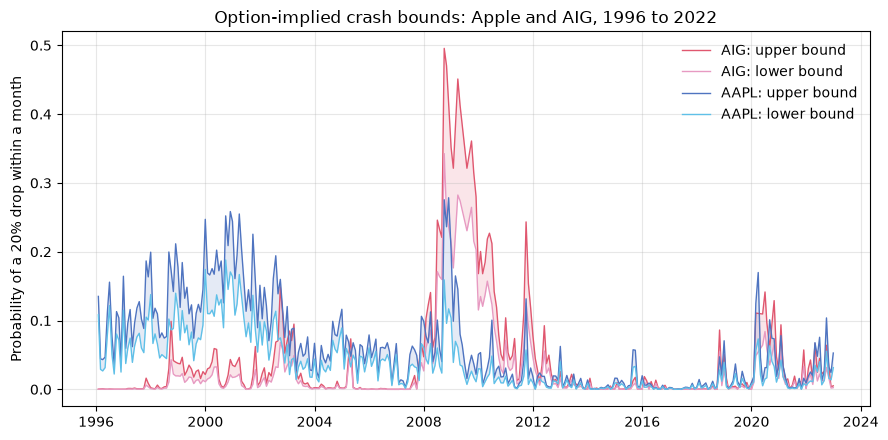

In [4]:
NAMES = [("AIG", "#e0576f", "#e79ac2"), ("AAPL", "#4f74c0", "#5fc0e8")]


def figure1(bounds, start, end, title):
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for ticker, c_hi, c_lo in NAMES:
        s = bounds[
            (bounds["ticker"] == ticker)
            & (bounds["threshold"] == 0.80)
            & (bounds["days_to_maturity"] == 30)
            & (bounds["date"] >= start)
            & (bounds["date"] <= end)
        ].sort_values("date")
        ax.fill_between(s["date"], s["bound_lower"], s["bound_upper"], color=c_hi, alpha=0.15, linewidth=0)
        ax.plot(s["date"], s["bound_upper"], color=c_hi, lw=1.0, label=f"{ticker}: upper bound")
        ax.plot(s["date"], s["bound_lower"], color=c_lo, lw=1.0, label=f"{ticker}: lower bound")
    ax.set_ylabel("Probability of a 20% drop within a month")
    ax.set_title(title)
    ax.legend(frameon=False, loc="upper right")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    return fig


if HAVE_RESULTS:
    bounds = pd.read_parquet(OUTPUT_DIR / "single_name_bounds.parquet")
    figure1(bounds, "1996-01-01", "2022-12-31", "Option-implied crash bounds: Apple and AIG, 1996 to 2022")
    plt.show()

The two names tell the paper's story. AIG's band explodes in the autumn of
2008, when its options priced the crash that was happening; Apple's
spikes are the dot-com bust and 2008, and its bounds are otherwise the
quieter of the two after 2010. The band is the honest part of the answer:
the width is what the options cannot tell you, which is how the stock and
the market co-move in a crash.

The same chart through the latest surface:

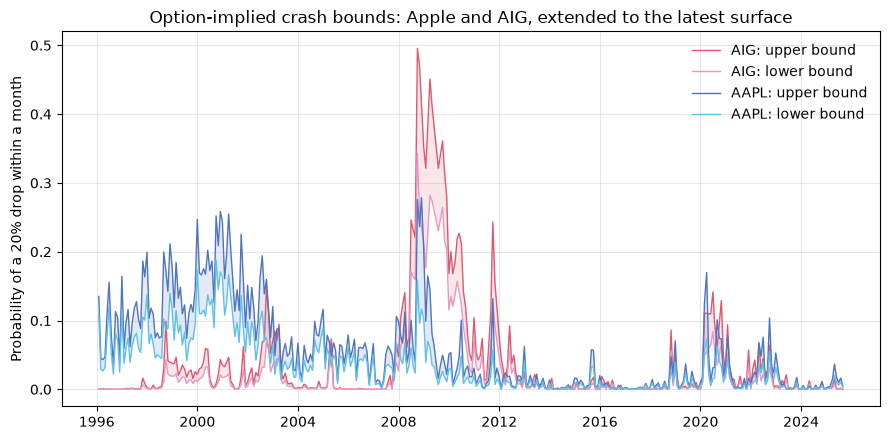

,,bound_lower,prob_riskneutral,bound_upper
ticker,days_to_maturity,,,
AAPL,30,0.0029,0.0040,0.0047
AIG,30,0.0000,0.0000,0.0000
AAPL,91,0.0452,0.0718,0.0873
AIG,91,0.0145,0.0255,0.0325


In [5]:
if HAVE_RESULTS:
    figure1(bounds, "1996-01-01", bounds["date"].max(), "Option-implied crash bounds: Apple and AIG, extended to the latest surface")
    plt.show()
    latest = bounds[(bounds["date"] == bounds["date"].max()) & (bounds["threshold"] == 0.80)]
    display(latest.set_index(["ticker", "days_to_maturity"])[["bound_lower", "prob_riskneutral", "bound_upper"]])

## The index on its own, against Martin's published series

When the "name" is the market itself, the two returns are comonotonic and
the lower bound holds with equality (the paper's equation 7), so the
index's crash probability is a point, not a band. That is the number
guide 02 computed from the exchange's settlement prices for one session.
Here it is from the vendor's surface for every day since 1996, under
three sets of beliefs:

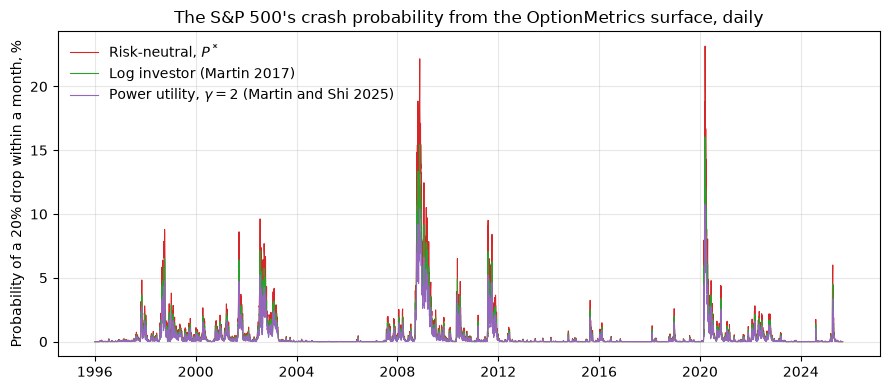

In [6]:
if HAVE_RESULTS:
    index = pd.read_parquet(OUTPUT_DIR / "index_crash_probabilities.parquet")
    m1 = index[(index["days_to_maturity"] == 30) & (index["threshold"] == 0.80)].set_index("date")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(m1.index, 100 * m1["prob_riskneutral"], label="Risk-neutral, $P^*$", color="#d62728", lw=0.8)
    ax.plot(m1.index, 100 * m1["prob_log_utility"], label="Log investor (Martin 2017)", color="#2ca02c", lw=0.8)
    ax.plot(m1.index, 100 * m1["prob_power_utility"], label="Power utility, $\\gamma=2$ (Martin and Shi 2025)", color="#9467bd", lw=0.8)
    ax.set_ylabel("Probability of a 20% drop within a month, %")
    ax.set_title("The S&P 500's crash probability from the OptionMetrics surface, daily")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()

Martin (2017) publishes exactly the middle series, the log investor's
probability of a 20% drop, averaged by month, from January 1996 to
January 2012 (`data_manual/martin_2017/crashprob.csv`). His inputs are
S&P 500 index options from the same vendor, so this is the check on the
single-name half of the pipeline:

Months in the overlap: 193
Correlation with Martin's series: 0.956
Median absolute gap: 0.27 percentage points; mean: 0.35


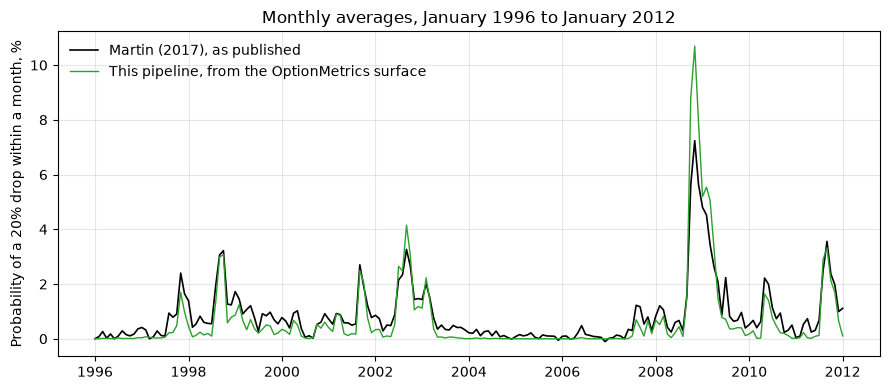

,ours,Martin
date,,
2008-01-01,0.0068,0.0083
2008-02-01,0.0052,0.0121
2008-03-01,0.0082,0.0106
2008-04-01,0.0017,0.0042
2008-05-01,0.0004,0.0024
2008-06-01,0.0022,0.0060
2008-07-01,0.0044,0.0067
2008-08-01,0.0008,0.0030
2008-09-01,0.0154,0.0160


In [7]:
if HAVE_RESULTS:
    martin = pd.read_csv(MANUAL_DATA_DIR / "martin_2017" / "crashprob.csv")
    ours = m1.reset_index()
    ours["year"], ours["month"] = ours["date"].dt.year, ours["date"].dt.month
    monthly = ours.groupby(["year", "month"])["prob_log_utility"].mean().reset_index()
    merged = monthly.merge(martin[["year", "month", "m1"]], on=["year", "month"])
    merged["date"] = pd.to_datetime(merged[["year", "month"]].assign(day=1))
    gap = (merged["prob_log_utility"] - merged["m1"]).abs()
    print(f"Months in the overlap: {len(merged)}")
    print(f"Correlation with Martin's series: {np.corrcoef(merged['prob_log_utility'], merged['m1'])[0, 1]:.3f}")
    print(f"Median absolute gap: {100 * gap.median():.2f} percentage points; mean: {100 * gap.mean():.2f}")
    fig, ax = plt.subplots(figsize=(9, 4))
    ax.plot(merged["date"], 100 * merged["m1"], label="Martin (2017), as published", color="black", lw=1.2)
    ax.plot(merged["date"], 100 * merged["prob_log_utility"], label="This pipeline, from the OptionMetrics surface", color="#2ca02c", lw=1.0)
    ax.set_ylabel("Probability of a 20% drop within a month, %")
    ax.set_title("Monthly averages, January 1996 to January 2012")
    ax.legend(frameon=False)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    plt.show()
    display(merged[merged["year"].isin([2008, 2011])].set_index("date")[["prob_log_utility", "m1"]].rename(
        columns={"prob_log_utility": "ours", "m1": "Martin"}))

The two series move together, and the crises line up: October 2008, the
flash crash of May 2010, August 2011. Ours runs a little below Martin's in
calm months and above it in the worst ones, and the first of those is the
surface again: with its strikes stopping near 92% of the spot, the flat
extrapolation into the tail understates the price of deep puts in quiet
markets, and the probability of a drop that starts beyond the last strike
comes out small. Martin works from the raw option quotes, which reach
further. The exchange's settlement prices in guides 01 and 02 are the
cure.

## Where this leaves the homework

Part D asks for one thing: the `WHERE` clause of the surface query in
`src/pull_optionmetrics.py`, which selects the three securities, the two
maturities, and the sample window from the vendor's yearly tables. Two
tests run it against a small in-memory database with the WRDS layout, as
HW 1 tested its queries. Then `uv run doit single_names` pulls the
surface and runs the chain that made every chart on this page, and the
last test checks the index probability against Martin's series as above.